# Stage 03 - Prepare hydro, solar, and wind availability

This notebook creates hourly `p_max_pu` profiles for every hydro, solar, and onshore-wind plant in the 2022 SNI fleet. It validates exact plant coverage, 8,760-hour alignment, finite values, and the physical range from zero to one.

These are availability constraints, not simulated generation. Annual energy and the 5% carrier gate are evaluated only after the network is solved in Stage 06.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.artifacts import format_preflight_report, run_preflight
from src.environment import check_environment, format_environment_report

environment = check_environment()
if not environment.ok:
    raise RuntimeError(format_environment_report(environment))
preflight = run_preflight("03_profiles", root=ROOT)
preflight.raise_for_errors()
print(format_environment_report(environment))
print(format_preflight_report(preflight))

Environment preflight: PASS
  environment: pypsa-earth-ec (expected pypsa-earth-ec)
  python: 3.11.14 (required >=3.10,<3.12)
  pypsa: 0.30.3 (>=0.25,<=0.30.3) [ok]
  numpy: 1.26.4 (<2) [ok]
  pandas: 2.3.3 (>=2) [ok]
  xarray: 2025.1.2 (>=2023.11.0,<=2025.1.2) [ok]
  h5netcdf: 1.7.3 (>=1) [ok]
  PyYAML: 6.0.3 (>=6) [ok]
  requests: 2.32.5 (>=2) [ok]
  jsonschema: 4.25.1 (>=4) [ok]
  nbformat: 5.10.4 (>=5) [ok]
  nbclient: 0.10.2 (>=0.10) [ok]
Artifact preflight: PASS (stage=03_profiles)
  not-required pypsa_earth_base_ec: stage does not require this artifact
  valid        renewable_profile_solar_ec: cached file verified
  not-required gadm_ecuador_41: stage does not require this artifact
  valid        renewable_profile_onwind_ec: cached file verified
  not-required demand_template_2013_ec: stage does not require this artifact
  not-required cenace_sni_2022_monthly_demand: stage does not require this artifact
  not-required cenace_2022_net_supply: stage does not require this artifact

## Hydrology method and evidence limits

The retained source has eight monthly flow proxy series. Each run-of-river plant uses its assigned series divided by its 95th percentile and clipped to `[0, 1]`. Reservoir plants first use a trailing three-month mean. Monthly values are anchored near mid-month and interpolated hourly, with edge values extended to the calendar boundaries.

All 65 hydro plants have an explicit assignment, but most are legacy regional proxies rather than measured plant inflows. Assignment basis and confidence are versioned instead of treating all manual aliases as high confidence. Sarapullo and Sabanilla are forced to zero before their official 2022 operating dates.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.availability import (
    attach_renewable_availability,
    build_hydro_availability,
    load_hydro_assignments,
    load_monthly_flows,
)

generators = pd.read_csv(ROOT / "data/processed/generation/generators_2022.csv")
flows = load_monthly_flows(ROOT / "data/raw/generation/caudals.csv")
assignments = load_hydro_assignments(ROOT / "data/interim/generation/hydro_profile_assignments_2022.csv")
hydro, hydro_diagnostics = build_hydro_availability(generators, flows, assignments, year=2022)
hydro_diagnostics.groupby("confidence", as_index=False).agg(
    plants=("plant_id", "size"),
    effective_capacity_mw=("effective_capacity_mw", "sum"),
)

,confidence,plants,effective_capacity_mw
0,high,4,1980.00
1,low,56,1110.71
2,medium,5,2053.90


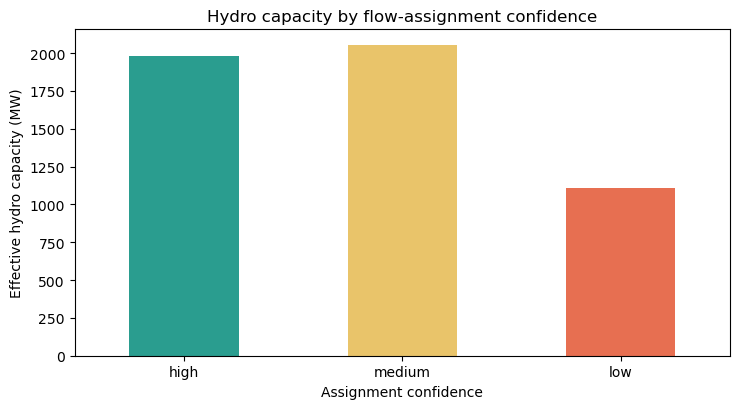

In [3]:
figure_dir = ROOT / "reports/figures/phase_04"
figure_dir.mkdir(parents=True, exist_ok=True)
confidence_order = ["high", "medium", "low"]
confidence = hydro_diagnostics.groupby("confidence")["effective_capacity_mw"].sum().reindex(confidence_order)
ax = confidence.plot.bar(figsize=(7.5, 4.2), color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.set_ylabel("Effective hydro capacity (MW)")
ax.set_xlabel("Assignment confidence")
ax.set_title("Hydro capacity by flow-assignment confidence")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(figure_dir / "hydro_assignment_confidence.png", dpi=160)
plt.show()

## Solar and onshore-wind weather profiles

The external NetCDF files contain 2013 ERA5-derived provincial profiles. Phase 4 does not claim that 2013 weather is observed 2022 weather. It preserves this known weather year as a transparent meteorological scenario, maps each plant by province, and transfers the 8,760 hourly positions to the 2022 non-leap calendar. Galapagos remains outside the SNI plant fleet. Huascachaca is forced to zero before its first official December 2022 unit-group date; the conflicting staged event and plant capacities remain separate evidence rather than an invented fractional trajectory.

In [4]:
renewable, renewable_diagnostics = attach_renewable_availability(
    generators,
    solar_profile_path=ROOT / "data/raw/cutouts/solar.nc",
    wind_profile_path=ROOT / "data/raw/cutouts/onwind.nc",
    target_year=2022,
)
renewable_diagnostics.groupby("carrier", as_index=False).agg(
    plants=("plant_id", "size"),
    mean_p_max_pu=("mean_p_max_pu", "mean"),
    maximum_p_max_pu=("maximum_p_max_pu", "max"),
)

C:\Users\fpenaherrera_vaca\.conda\envs\pypsa-earth-ec\Lib\site-packages\xarray\backends\plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


,carrier,plants,mean_p_max_pu,maximum_p_max_pu
0,onwind,2,0.006666,0.331636
1,solar,24,0.157453,0.780173


## Representative one-week profiles

The four panels below show the first seven days of 2022 for one plant of each requested profile type. Selection is deterministic: the largest full-year solar plant, the largest full-year wind plant, the largest reservoir hydro plant, and the largest run-of-river hydro plant by effective capacity. Full-year renewable plants are used so the January window is not dominated by an in-year commissioning mask. All panels share the same time axis and use the same `[0, 1]` availability scale.

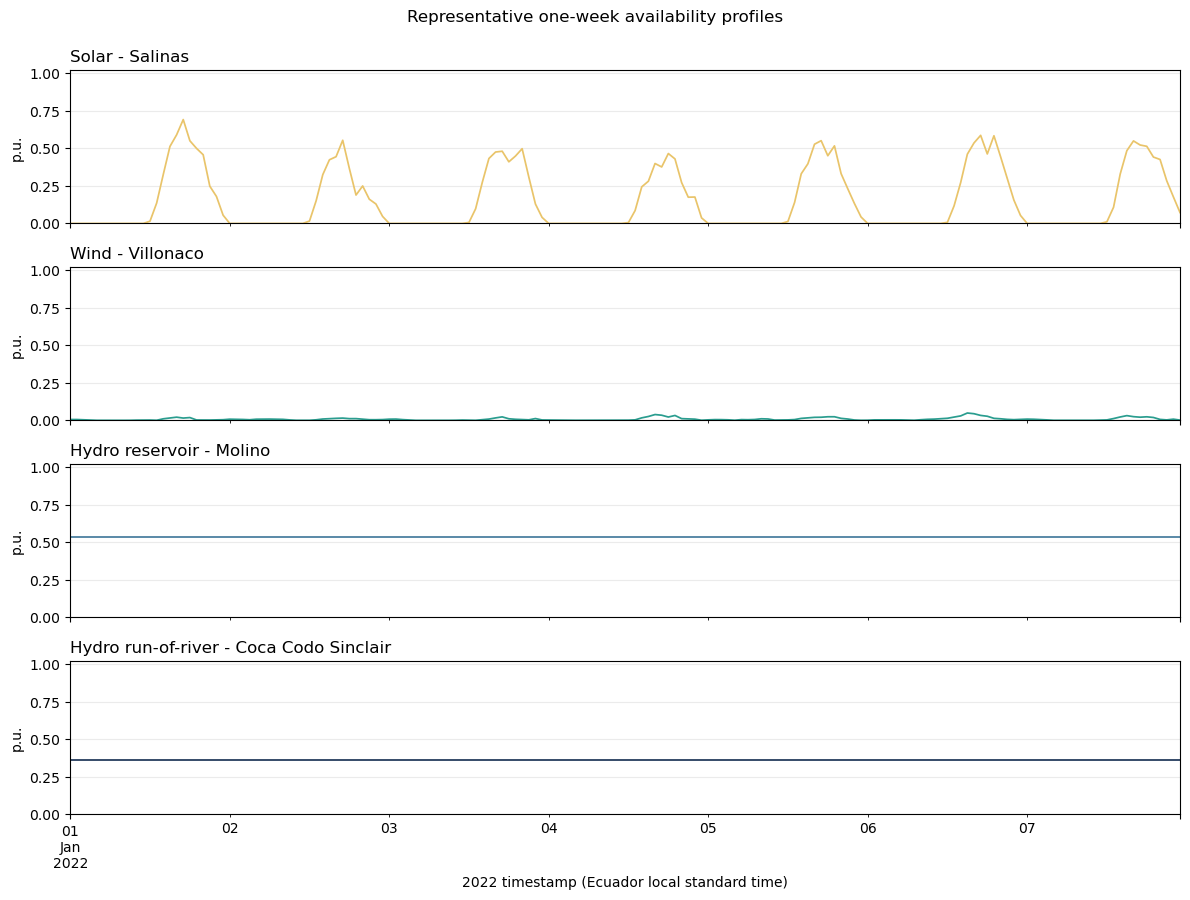

,profile_type,plant
0,solar,Salinas
1,wind,Villonaco
2,hydro_reservoir,Molino
3,hydro_run_of_river,Coca Codo Sinclair


In [5]:
week = slice("2022-01-01 00:00:00", "2022-01-07 23:00:00")
full_year = generators[generators["operating_start_date_2022"] == "2022-01-01"]
solar_example = full_year[full_year["carrier"] == "solar"].sort_values(["p_nom_mw", "plant_id"], ascending=[False, True]).iloc[0]
wind_example = full_year[full_year["carrier"] == "onwind"].sort_values(["p_nom_mw", "plant_id"], ascending=[False, True]).iloc[0]
reservoir_example = hydro_diagnostics[hydro_diagnostics["hydro_model"] == "reservoir_3_month_rolling"].sort_values(["effective_capacity_mw", "plant_id"], ascending=[False, True]).iloc[0]
run_of_river_example = hydro_diagnostics[hydro_diagnostics["hydro_model"] == "run_of_river"].sort_values(["effective_capacity_mw", "plant_id"], ascending=[False, True]).iloc[0]

examples = [
    (renewable[solar_example["plant_id"]], f"Solar - {solar_example['name']}", "#e9c46a"),
    (renewable[wind_example["plant_id"]], f"Wind - {wind_example['name']}", "#2a9d8f"),
    (hydro[reservoir_example["plant_id"]], f"Hydro reservoir - {reservoir_example['plant_name']}", "#457b9d"),
    (hydro[run_of_river_example["plant_id"]], f"Hydro run-of-river - {run_of_river_example['plant_name']}", "#1d3557"),
]
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for axis, (series, title, color) in zip(axes, examples):
    series.loc[week].plot(ax=axis, color=color, linewidth=1.25)
    axis.set_title(title, loc="left")
    axis.set_ylabel("p.u.")
    axis.set_ylim(0, 1.02)
    axis.grid(axis="y", alpha=0.25)
axes[-1].set_xlabel("2022 timestamp (Ecuador local standard time)")
fig.suptitle("Representative one-week availability profiles", y=0.995)
plt.tight_layout()
plt.savefig(figure_dir / "weekly_example_availability_profiles.png", dpi=160, bbox_inches="tight")
plt.show()
pd.DataFrame({
    "profile_type": ["solar", "wind", "hydro_reservoir", "hydro_run_of_river"],
    "plant": [solar_example["name"], wind_example["name"], reservoir_example["plant_name"], run_of_river_example["plant_name"]],
})

## Profile diagnostics and outputs

Duration curves reveal the range and shape of the constraints without implying generation dispatch. The large hourly CSVs are reproducible products and are intentionally ignored by Git; downstream stages regenerate them through this notebook.

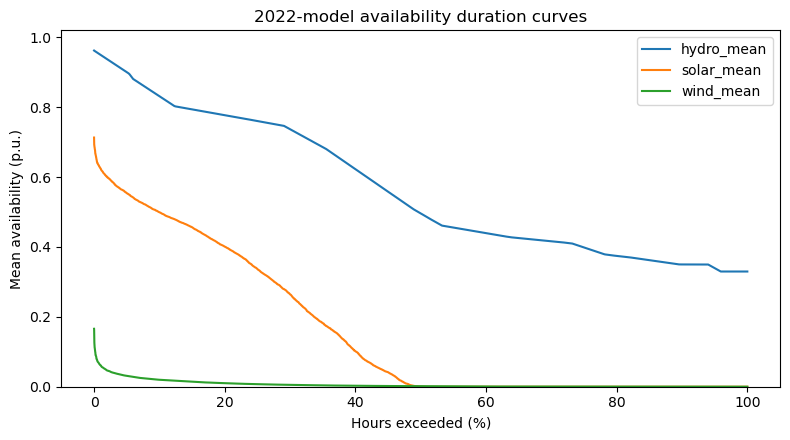

In [6]:
duration = pd.DataFrame({
    "hydro_mean": hydro.mean(axis=1).sort_values(ascending=False).to_numpy(),
    "solar_mean": renewable.loc[:, renewable_diagnostics.query("carrier == 'solar'")["plant_id"]].mean(axis=1).sort_values(ascending=False).to_numpy(),
    "wind_mean": renewable.loc[:, renewable_diagnostics.query("carrier == 'onwind'")["plant_id"]].mean(axis=1).sort_values(ascending=False).to_numpy(),
})
duration.index = 100 * duration.index / (len(duration) - 1)
ax = duration.plot(figsize=(8, 4.5))
ax.set_xlabel("Hours exceeded (%)")
ax.set_ylabel("Mean availability (p.u.)")
ax.set_title("2022-model availability duration curves")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(figure_dir / "availability_duration_curves.png", dpi=160)
plt.show()

In [7]:
output_dir = ROOT / "data/processed/generation"
hydro.to_csv(output_dir / "hydro_availability_2022.csv", index_label="timestamp")
renewable.to_csv(output_dir / "renewable_availability_2022.csv", index_label="timestamp")

summary = {
    "hydro_plants": hydro.shape[1],
    "solar_plants": int((renewable_diagnostics["carrier"] == "solar").sum()),
    "wind_plants": int((renewable_diagnostics["carrier"] == "onwind").sum()),
    "snapshots": hydro.shape[0],
    "hydro_minimum_pu": float(hydro.min().min()),
    "hydro_maximum_pu": float(hydro.max().max()),
    "renewable_minimum_pu": float(renewable.min().min()),
    "renewable_maximum_pu": float(renewable.max().max()),
    "missing_values": int(hydro.isna().sum().sum() + renewable.isna().sum().sum()),
    "weather_year": int(renewable_diagnostics["weather_year"].iloc[0]),
    "simulation_year": int(renewable_diagnostics["simulation_year"].iloc[0]),
}
pd.Series(summary, name="value")

hydro_plants              65.000000
solar_plants              24.000000
wind_plants                2.000000
snapshots               8760.000000
hydro_minimum_pu           0.000000
hydro_maximum_pu           1.000000
renewable_minimum_pu       0.000000
renewable_maximum_pu       0.780173
missing_values             0.000000
weather_year            2013.000000
simulation_year         2022.000000
Name: value, dtype: float64

## Phase 06B wind and biomass candidate review

The legacy `onwind.nc` profile is retained as rejected evidence because its plant-level energy is implausibly low. This cell compares it with optional NLR Sup3rWind South America single-location CSVs when they are present under `data/raw/cutouts/nlr_sup3rwind/`. The API URL is recorded but no credentialed download is attempted automatically. The candidate is selected only from an available source and its annual energy is reported before any calibration control.

Biomass uses the official ARCONEL monthly shape as a temporal constraint and the CENACE net annual value as a calibration control. The gross ARCONEL total is not presented as the independent CENACE target.

In [8]:
from src.phase06b import (build_biomass_availability, load_monthly_biomass_shape, nlr_sup3rwind_csv_url, read_nlr_wind_csv, scale_profile_to_annual_energy, wind_speed_to_pu)
from src.phase06d import candidate_name, candidate_settings, apply_bounded_profile_factor
import json

comparison_dir = ROOT / 'results/phase_06b'
comparison_dir.mkdir(parents=True, exist_ok=True)
wind_reference_gwh = 57.00
wind_rows = []
nlr_profiles = {}
nlr_dir = ROOT / 'data/raw/cutouts/nlr_sup3rwind'
for row in generators.loc[generators.carrier.eq('onwind')].itertuples(index=False):
    legacy = renewable[row.plant_id]
    legacy_gwh = float((legacy * row.p_nom_mw).sum() / 1000.0)
    csv_path = nlr_dir / f'{row.plant_id}_2022.csv'
    nlr_gwh = None
    if csv_path.exists():
        nlr_raw = read_nlr_wind_csv(csv_path, year=2022)['wind_speed_m_s']
        if not nlr_raw.index.equals(renewable.index): raise ValueError(f'Incomplete or misaligned NLR calendar for {row.plant_id}')
        nlr_profile = wind_speed_to_pu(nlr_raw)
        nlr_gwh = float((nlr_profile * row.p_nom_mw).sum() / 1000.0)
        nlr_profiles[row.plant_id] = nlr_profile.where(renewable.index >= pd.Timestamp(row.operating_start_date_2022), 0.0)
    wind_rows.append({'plant_id': row.plant_id, 'legacy_onwind_gwh': legacy_gwh, 'nlr_sup3rwind_gwh': nlr_gwh, 'nlr_url_template': nlr_sup3rwind_csv_url(row.longitude, row.latitude), 'reference_total_gwh': wind_reference_gwh})
wind_comparison = pd.DataFrame(wind_rows)
wind_candidate = 'legacy_onwind_nc'
if len(nlr_profiles) == int((generators.carrier == 'onwind').sum()):
    for plant_id, profile in nlr_profiles.items(): renewable[plant_id] = profile
    wind_candidate = 'nlr_sup3rwind_site_profiles'
settings = candidate_settings()
wind_comparison['candidate'] = candidate_name()
wind_comparison['pre_scaling_gwh'] = wind_comparison['nlr_sup3rwind_gwh'].fillna(wind_comparison['legacy_onwind_gwh'])
if candidate_name() == 'renewable-calibration' and nlr_profiles:
    settings['wind_factor'] = float(wind_reference_gwh / wind_comparison['pre_scaling_gwh'].sum())
if settings['wind_factor'] != 1.0:
    for plant_id in nlr_profiles:
        renewable[plant_id], _, _ = apply_bounded_profile_factor(renewable[plant_id], settings['wind_factor'])
wind_comparison['wind_factor'] = settings['wind_factor']
wind_comparison.to_csv(comparison_dir / f'wind_profile_source_comparison_2022_{candidate_name()}.csv', index=False)

biomass_source = load_monthly_biomass_shape(ROOT / 'data/raw/statistics/arconel_2022_biomass_monthly.csv')
biomass_target = 195.68 * settings['biomass_factor']
biomass_profiles, biomass_diagnostics = build_biomass_availability(renewable.index, generators, biomass_source, annual_net_target_gwh=biomass_target)
renewable = pd.concat([renewable, biomass_profiles], axis=1)
biomass_diagnostics.to_csv(comparison_dir / 'biomass_profile_diagnostics_2022.csv', index=False)
candidate_metadata = {'candidate': candidate_name(), 'wind_policy': wind_candidate, 'wind_reference_gwh': wind_reference_gwh, 'wind_factor': settings['wind_factor'], 'biomass_shape_source': 'ARCONEL Table 54', 'biomass_annual_control_gwh': biomass_target, 'biomass_factor': settings['biomass_factor'], 'biomass_control_status': 'calibration_input_not_independent_validation'}
(comparison_dir / 'profile_candidate_selection_2022.json').write_text(json.dumps(candidate_metadata, indent=2), encoding='utf-8')
# The profile review must precede the authoritative Stage 03 output write.
renewable.to_csv(ROOT / 'data/processed/generation/renewable_availability_2022.csv', index_label='timestamp')
display(wind_comparison); display(biomass_diagnostics)

,plant_id,legacy_onwind_gwh,nlr_sup3rwind_gwh,nlr_url_template,reference_total_gwh,candidate,pre_scaling_gwh,wind_factor
0,ec2022_030_Huascachaca,0.163446,37.962352,https://developer.nlr.gov/api/wind-toolkit/v2/...,57.0,renewable-calibration,37.962352,1.372016
1,ec2022_074_Villonaco,1.872949,3.582362,https://developer.nlr.gov/api/wind-toolkit/v2/...,57.0,renewable-calibration,3.582362,1.372016


,plant_id,p_nom_mw,carrier,source_boundary,annual_net_target_gwh
19,ec2022_022_San_Carlos,78.0,biomass,ARCONEL gross shape / CENACE net annual control,195.68
39,ec2022_045_Ecoelectric,36.5,biomass,ARCONEL gross shape / CENACE net annual control,195.68
44,ec2022_055_Ecudos_A_G,29.8,biomass,ARCONEL gross shape / CENACE net annual control,195.68
